# 04 — Stereo vision: two cameras gossip about depth

One camera sees directions. Two cameras can compare where the same thing appears and recover distance—assuming they agree on geometry, timing, and what “the same thing” means.

This practice follows the useful chain:

**left + right images → disparity → depth map → point cloud**

We will keep the scene synthetic so the true disparity is known. The computer therefore has fewer places to hide its crimes.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=3, suppress=True)

## 1. Stereo is binocular vision with paperwork

Two horizontally separated cameras see a nearby object at different horizontal positions. That shift is **disparity**. For a rectified stereo pair, corresponding points stay on the same image row, so matching searches sideways instead of wandering through the entire image.

- Larger disparity means the object is closer.
- Smaller disparity means it is farther away.
- Zero or uncertain disparity means distance is preparing to become somebody else's problem.

“Stereo detection” is sometimes used informally, but stereo itself estimates geometry. **Object detection** answers *what and where in the image?* Stereo answers *how far away?* They can cooperate without being the same job.

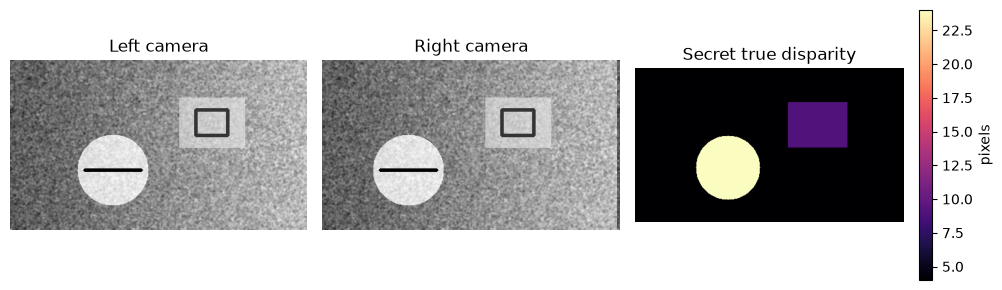

In [2]:
def make_stereo_scene(height=240, width=420, seed=8, objects=None, background_shift=4.0):
    """Create a rectified stereo pair with known piecewise-constant disparity."""
    rng = np.random.default_rng(seed)
    texture = rng.normal(125, 34, (height, width)).astype(np.float32)
    texture = cv2.GaussianBlur(texture, (0, 0), 1.0)
    texture += np.linspace(-28, 28, width, dtype=np.float32)[None, :]
    background = np.clip(texture, 0, 255).astype(np.uint8)

    left = background.copy()
    right = np.roll(background, -1 * background_shift, axis=1)
    true_disparity = np.full((height, width), background_shift, dtype=np.float32)

    if objects is None:
        objects = [
            # name, center, size/radius, intensity, disparity, shape
            ("far crate", (285, 88), (92, 70), 185, 9, "rectangle"),
            ("near moon", (145, 155), 50, 225, 24, "circle"),
        ]
    for name, center, size, intensity, disparity, shape in objects:
        left_mask = np.zeros_like(left)
        right_mask = np.zeros_like(right)
        right_center = (center[0] - disparity, center[1])
        if shape == "rectangle":
            half_w, half_h = size[0] // 2, size[1] // 2
            cv2.rectangle(left_mask, (center[0] - half_w, center[1] - half_h),
                          (center[0] + half_w, center[1] + half_h), 255, -1)
            cv2.rectangle(right_mask, (right_center[0] - half_w, right_center[1] - half_h),
                          (right_center[0] + half_w, right_center[1] + half_h), 255, -1)
        else:
            cv2.circle(left_mask, center, size, 255, -1)
            cv2.circle(right_mask, right_center, size, 255, -1)

        object_texture = np.clip(background.astype(float) * 0.45 + intensity * 0.55, 0, 255).astype(np.uint8)
        right_texture = np.roll(object_texture, -disparity, axis=1)
        left[left_mask > 0] = object_texture[left_mask > 0]
        right[right_mask > 0] = right_texture[right_mask > 0]
        true_disparity[left_mask > 0] = disparity

    # Details give matching something distinctive to hold onto.
    cv2.line(left, (105, 155), (185, 155), 45, 3)
    cv2.line(right, (81, 155), (161, 155), 45, 3)
    cv2.rectangle(left, (262, 70), (307, 106), 75, 3)
    cv2.rectangle(right, (253, 70), (298, 106), 75, 3)
    return left, right, true_disparity


left, right, true_disparity = make_stereo_scene()

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, image, title, cmap in zip(
    axes,
    (left, right, true_disparity),
    ("Left camera", "Right camera", "Secret true disparity"),
    ("gray", "gray", "magma"),
):
    shown = ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(axes[2].images[0], ax=axes[2], fraction=0.046, label="pixels")
plt.tight_layout()
plt.show()

> **What do the disparity colors mean?** They show horizontal shift in **pixels**, not distance in meters. Dark background = `4 px` disparity (farthest), purple rectangle = `9 px`, and bright circle = `24 px` (closest). With the later camera settings `f = 180 px` and `B = 0.12 m`, `Z = fB/d` places them at approximately `5.4 m`, `2.4 m`, and `0.9 m`. So brighter means **more sideways shift and therefore closer**. “Secret” means we created these values ourselves and know the answer before asking StereoBM to guess.

### Follow one object with your eyes

The near circle moves farther left in the right image than the farther rectangle. Nothing in the world moved; the observer moved sideways. Stereo geometry enjoys blaming the camera for everything.

**Practice:** change the disparities `9` and `24` in the scene generator. Predict which object will appear closer before looking at the maps.

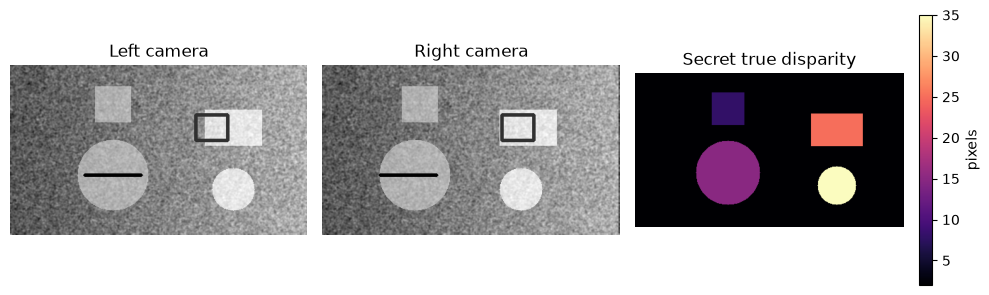

In [3]:
left_p, right_p, true_disparity_p = make_stereo_scene(
    background_shift=2,
    objects=[
        # name, center, size/radius, intensity, disparity, shape
        ("square", (145, 55), (50, 50), 185, 8, "rectangle"),
        ("rec", (315, 88), (80, 50), 225, 25, "rectangle"),
        ("near moon", (315, 175), 30, 225, 35, "circle"),
        ("far moon", (145, 155), 50, 185, 15, "circle"),
    ]
)

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, image, title, cmap in zip(
    axes,
    (left_p, right_p, true_disparity_p),
    ("Left camera", "Right camera", "Secret true disparity"),
    ("gray", "gray", "magma"),
):
    shown = ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(axes[2].images[0], ax=axes[2], fraction=0.046, label="pixels")
plt.tight_layout()
plt.show()

## 2. Block matching: slide a small window and distrust everybody

For one patch in the left image, try candidate horizontal shifts in the right image. A simple matcher computes the **Sum of Absolute Differences (SAD)**: subtract corresponding pixel values, take their absolute values, and add them. The shift with the smallest cost wins. SAD is only an acronym; nobody needs to become emotionally involved except perhaps the mismatched pixels.

A single pixel is often ambiguous. A patch provides context—but a larger patch may cross object boundaries and mix different depths. Every solution arrives carrying a smaller problem under its coat.

### What the matcher actually does

For a chosen left-image point `(x, y)`:

1. Build a small patch centred at `(x, y)` in the left image.
2. Start with a candidate patch at the same `(x, y)` in the right image.
3. Keep the same row `y` and move the right patch left one pixel at a time: `(x − 1, y)`, `(x − 2, y)`, and so on.
4. At every position, calculate SAD between the frozen left patch and the current right patch.
5. Choose the right patch with the smallest SAD—the least suspicious candidate.
6. The horizontal shift between the two patch centres is the estimated disparity.

Our search uses disparities from `0` to `40`, so it checks `x`, `x − 1`, …, `x − 40`. For the near circle, the best match moves from `x = 145` to `x = 121`, giving disparity `145 − 121 = 24 px`.

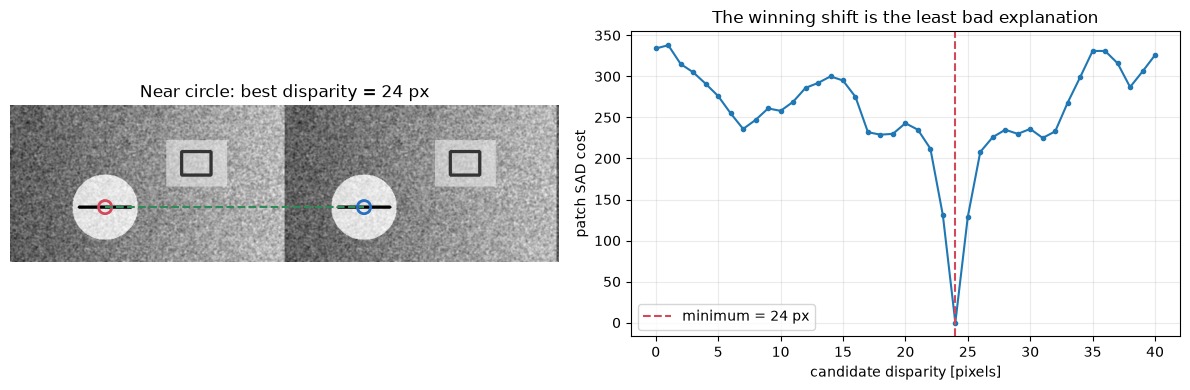

In [4]:
def sad_cost_curve(left_image, right_image, point, disparities, block_size=11):
    """Return SAD costs for matching one left-image patch along its scanline."""
    x, y = point
    radius = block_size // 2
    left_patch = left_image[y - radius:y + radius + 1, x - radius:x + radius + 1].astype(float)
    costs = []
    for disparity in disparities:
        candidate_x = x - disparity
        right_patch = right_image[
            y - radius:y + radius + 1,
            candidate_x - radius:candidate_x + radius + 1,
        ].astype(float)
        costs.append(np.abs(left_patch - right_patch).sum())
    return np.asarray(costs)


def match_and_plot_patch(
        left_image, right_image, match_point, candidate_disparities,
        block_size=11, point_name="selected point",
):
    """Find and visualize the lowest-SAD horizontal match for one point."""
    sad_costs = sad_cost_curve(
        left_image,
        right_image,
        match_point,
        candidate_disparities,
        block_size,
    )
    best_disparity = candidate_disparities[np.argmin(sad_costs)]
    right_match_x = match_point[0] - best_disparity

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(np.hstack([left_image, right_image]), cmap="gray")
    axes[0].scatter(*match_point, s=90, facecolors="none", edgecolors="#D1495B", linewidth=2)
    axes[0].scatter(
        left_image.shape[1] + right_match_x,
        match_point[1],
        s=90,
        facecolors="none",
        edgecolors="#276FBF",
        linewidth=2,
    )
    axes[0].plot(
        [match_point[0], left_image.shape[1] + right_match_x],
        [match_point[1], match_point[1]],
        linestyle="--",
        color="#2E8B57",
    )
    axes[0].set_title(f"{point_name}: best disparity = {best_disparity} px")
    axes[0].axis("off")

    axes[1].plot(candidate_disparities, sad_costs, "o-", markersize=3)
    axes[1].axvline(
        best_disparity,
        color="#D1495B",
        linestyle="--",
        label=f"minimum = {best_disparity} px",
    )
    axes[1].set(
        xlabel="candidate disparity [pixels]",
        ylabel="patch SAD cost",
        title="The winning shift is the least bad explanation",
    )
    axes[1].grid(alpha=0.25)
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    return {"best_disparity": best_disparity, "sad_costs": sad_costs}


candidate_disparities = np.arange(0, 41)
circle_match = match_and_plot_patch(
    left,
    right,
    match_point=(145, 155),
    candidate_disparities=candidate_disparities,
    block_size=11,
    point_name="Near circle",
)

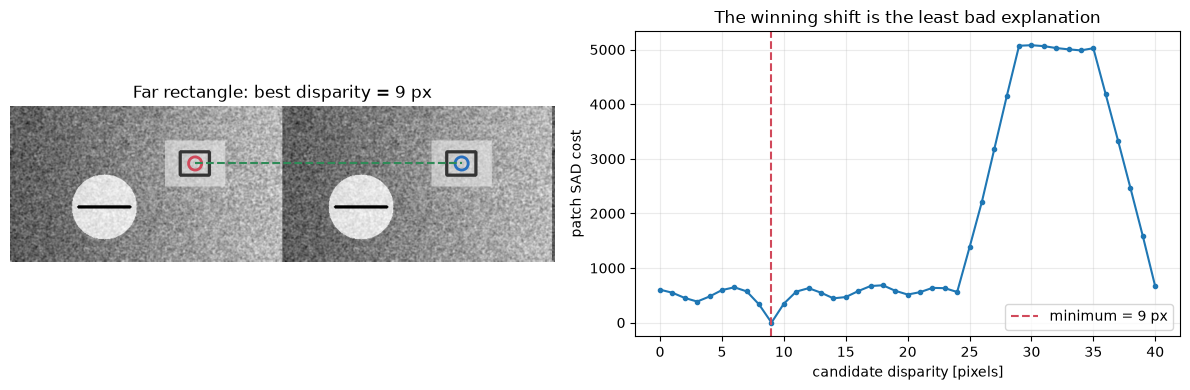

In [5]:
rectangle_match = match_and_plot_patch(
    left,
    right,
    match_point=(285, 88),
    candidate_disparities=candidate_disparities,
    block_size=11,
    point_name="Far rectangle",
)

## 3. From one patch to a disparity map

OpenCV's `StereoBM` repeats block matching across the image. The result is dense-ish rather than truly dense: textureless areas, occlusions, borders, and repeated patterns can produce invalid or noisy estimates.

The matcher returns fixed-point disparities scaled by `16`, an OpenCV naming-and-representation trap placed here to keep us emotionally alert.

> **Why does the estimated map have holes?** StereoBM is allowed to say “I do not trust this pixel.” It rejects matches when a patch has too little texture, when several candidate shifts look almost equally good, or when correspondence is impossible near borders and occlusions. We display these invalid values in gray. They mean **unknown disparity**, not a special distance.

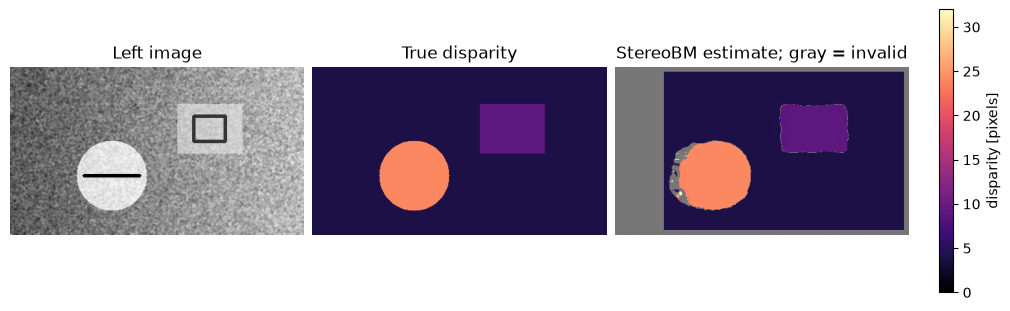

Trusted matches inside the safe area: 98.2%
Mean absolute disparity error for those matches: 0.21 px


In [6]:
# Search disparities 0...63 using a 15×15 comparison block.
num_disparities = 64
block_size = 15
stereo = cv2.StereoBM_create(numDisparities=num_disparities, blockSize=block_size)

# Reject nearly uniform patches: without texture, many horizontal shifts look identical.
stereo.setTextureThreshold(5)

# Accept a match only when the best candidate wins clearly enough over alternatives.
# A larger value is stricter and usually creates more invalid pixels.
stereo.setUniquenessRatio(8)

# OpenCV stores StereoBM disparity with 4 fractional bits, hence division by 16.
estimated_disparity = stereo.compute(left, right).astype(np.float32) / 16.0

# With the default minimum disparity of 0, non-positive values mean no trusted match.
valid_disparity = estimated_disparity > 0

# Make missing values visibly gray instead of letting them masquerade as mysterious white objects.
disparity_cmap = plt.colormaps["magma"].copy()
disparity_cmap.set_bad("#777777")

fig, axes = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
axes[0].imshow(left, cmap="gray")
axes[0].set_title("Left image")
truth_plot = axes[1].imshow(true_disparity, cmap="magma", vmin=0, vmax=32)
axes[1].set_title("True disparity")
estimate_plot = axes[2].imshow(
    np.where(valid_disparity, estimated_disparity, np.nan),
    cmap=disparity_cmap,
    vmin=0,
    vmax=32,
)
axes[2].set_title("StereoBM estimate; gray = invalid")
for ax in axes:
    ax.axis("off")
fig.colorbar(estimate_plot, ax=axes[1:], fraction=0.025, label="disparity [pixels]")
plt.show()

# A block needs half its width around the centre. The left border also needs
# room for the complete 0...63 pixel search in the right image.
block_radius = block_size // 2
left_margin = num_disparities + block_radius
interior = np.zeros_like(valid_disparity)
interior[
    block_radius:-block_radius,
    left_margin:-block_radius,
] = True

# Evaluate only pixels that are inside the safe area and trusted by StereoBM.
evaluation_mask = valid_disparity & interior
trusted_inside_ratio = evaluation_mask.sum() / interior.sum()
mae = np.mean(np.abs(estimated_disparity[evaluation_mask] - true_disparity[evaluation_mask]))
print(f"Trusted matches inside the safe area: {trusted_inside_ratio:.1%}")
print(f"Mean absolute disparity error for those matches: {mae:.2f} px")

> **What is the safe area?** A `15×15` block needs `7 px` around its centre, so the top, bottom, and right edges cannot be evaluated all the way to the border. The left edge loses even more space: StereoBM may search as far as `63 px` left in the right image, so it needs roughly `64 + 7 = 71 px` of room. We exclude those geometrically unfair borders before judging the matcher.

> **What does the percentage mean?** “Trusted matches inside the safe area” is the fraction of those remaining pixels for which StereoBM returned a positive disparity it accepted. The other safe-area pixels were rejected because the texture was weak, the winner was not unique enough, or matching still failed. The reported mean error is calculated only for accepted matches—it measures how accurate the answers were, while the percentage measures how often StereoBM was willing to answer.

### Practice: block-size diplomacy

Compare small and large blocks. Small blocks can preserve boundaries but are easier to confuse; large blocks are steadier but may flatten thin objects and mix foreground with background.

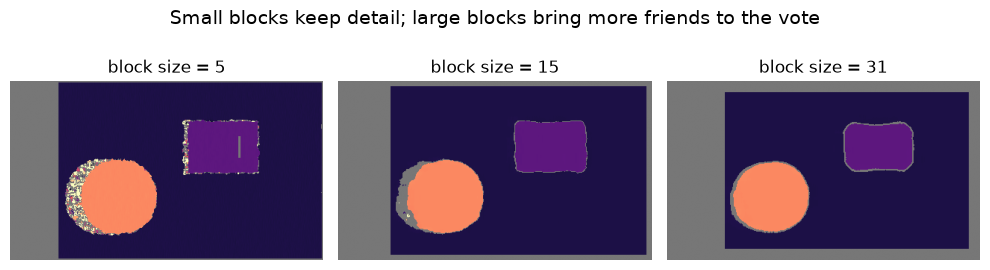

In [7]:
block_sizes = (5, 15, 31)
fig, axes = plt.subplots(1, len(block_sizes), figsize=(10, 3))
for ax, block_size in zip(axes, block_sizes):
    matcher = cv2.StereoBM_create(numDisparities=64, blockSize=block_size)
    matcher.setTextureThreshold(5)
    disparity = matcher.compute(left, right).astype(np.float32) / 16.0
    ax.imshow(np.where(disparity > 0, disparity, np.nan), cmap=disparity_cmap, vmin=0, vmax=32)
    ax.set_title(f"block size = {block_size}")
    ax.axis("off")
fig.suptitle("Small blocks keep detail; large blocks bring more friends to the vote", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Disparity becomes metric depth

For a rectified pair with focal length `f` in pixels and camera baseline `B` in meters:

The **baseline** is the physical distance between the two camera optical centres—`0.12 m` in our experiment. A larger baseline produces more disparity for the same depth, which can improve distance sensitivity, but it also increases viewpoint differences, occlusions, and the chance that one camera sees something the other does not.

`depth Z = f · B / disparity`

This is why calibration matters again. Disparity is measured from images; focal length and baseline turn it into meters. Depth is inversely proportional to disparity, so one pixel of disparity error becomes increasingly expensive far away.

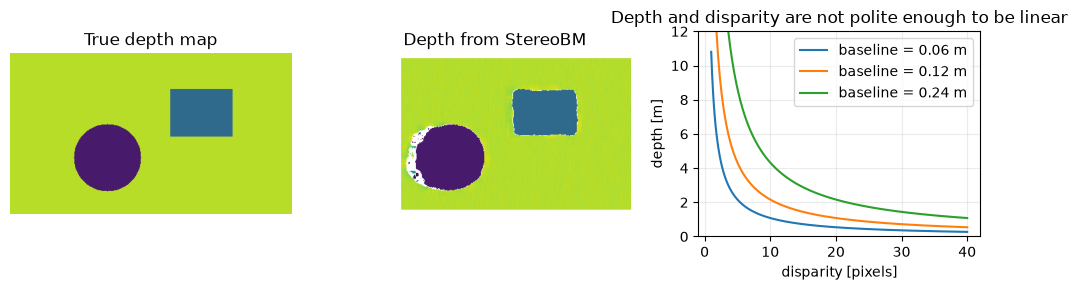

In [8]:
focal_length_px = 180.0
baseline_m = 0.12

true_depth = focal_length_px * baseline_m / true_disparity
estimated_depth = np.full_like(estimated_disparity, np.nan)
estimated_depth[valid_disparity] = focal_length_px * baseline_m / estimated_disparity[valid_disparity]

disparity_axis = np.linspace(1, 40, 300)
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(true_depth, cmap="viridis", vmin=0.5, vmax=6)
axes[0].set_title("True depth map")
axes[1].imshow(estimated_depth, cmap="viridis", vmin=0.5, vmax=6)
axes[1].set_title("Depth from StereoBM")
for baseline in (0.06, 0.12, 0.24):
    axes[2].plot(disparity_axis, focal_length_px * baseline / disparity_axis,
                 label=f"baseline = {baseline:.2f} m")
axes[2].set(xlabel="disparity [pixels]", ylabel="depth [m]",
            title="Depth and disparity are not polite enough to be linear")
axes[2].set_ylim(0, 12)
axes[2].grid(alpha=0.25)
axes[2].legend()
for ax in axes[:2]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Depth map → point cloud

A depth map stores one distance per pixel. Combine each pixel `(u, v)` with its depth and camera intrinsics, and it becomes a 3D point `(X, Y, Z)` in the camera frame.

The result is a **point cloud**: not a solid object, just many measured surface samples floating together with impressive confidence.

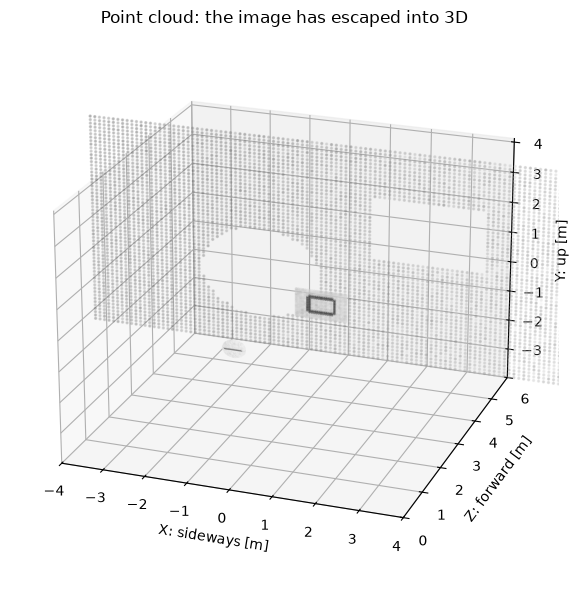

In [9]:
height, width = true_depth.shape
cx, cy = width / 2, height / 2
v, u = np.mgrid[0:height, 0:width]
z = true_depth
x = (u - cx) * z / focal_length_px
y = (v - cy) * z / focal_length_px

sample = (u % 4 == 0) & (v % 4 == 0)
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")
colors = left[sample]
ax.scatter(x[sample], z[sample], -y[sample], c=colors, cmap="gray", s=2, alpha=0.65)
ax.set(xlabel="X: sideways [m]", ylabel="Z: forward [m]", zlabel="Y: up [m]",
       title="Point cloud: the image has escaped into 3D")
ax.set_xlim(-4, 4)
ax.set_ylim(0, 6)
ax.view_init(elev=22, azim=-70)
plt.tight_layout()
plt.show()

## 6. Active infrared: give blank surfaces artificial freckles

A common active-stereo device contains **one infrared projector and two infrared cameras**. The projector shines an invisible dot pattern onto the scene; both IR cameras photograph the reflected pattern from slightly different positions and perform the same disparity search we used above.

The dots are **not heat**. They are near-infrared illumination—more like an invisible flashlight covered with freckles. An RGB camera may also be present, but it provides normal color rather than the stereo depth itself.

Why bother? Passive stereo depends on visible texture. A plain wall gives many identical patches, so every candidate shift looks equally plausible. Projected dots make local patches distinctive. The projector does not directly measure distance; it merely gives the two cameras better evidence to argue about.

Sunlight can overwhelm the IR pattern, reflective or transparent surfaces remain troublesome, and multiple active devices may interfere. Technology has once again declined to provide a free lunch.

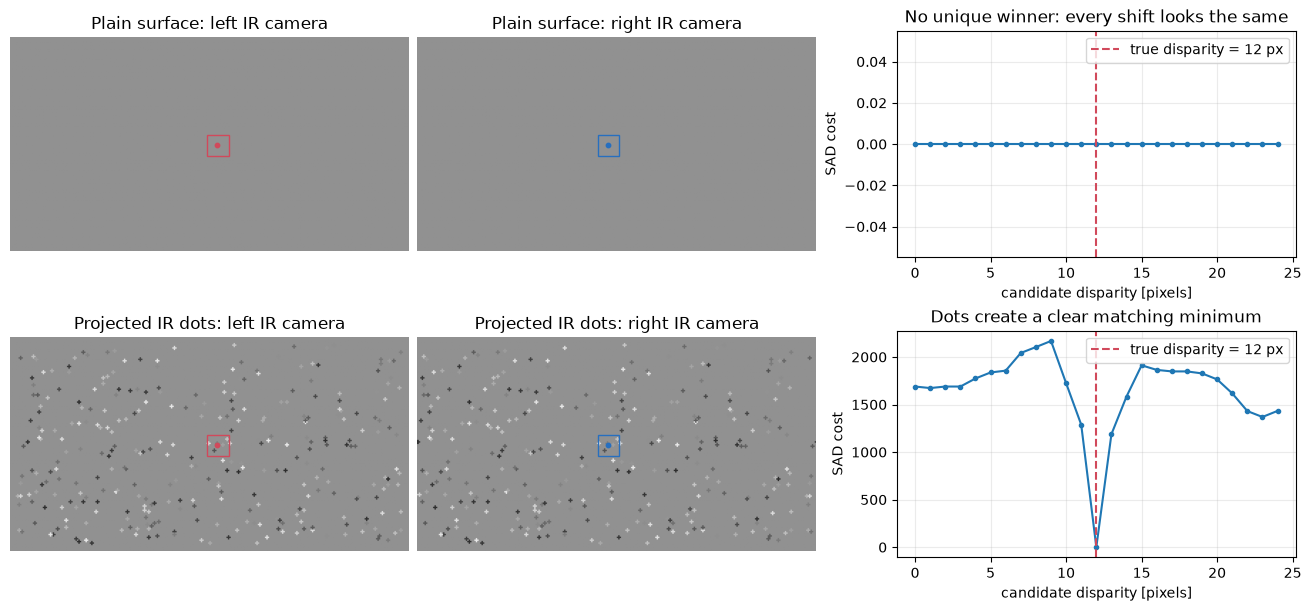

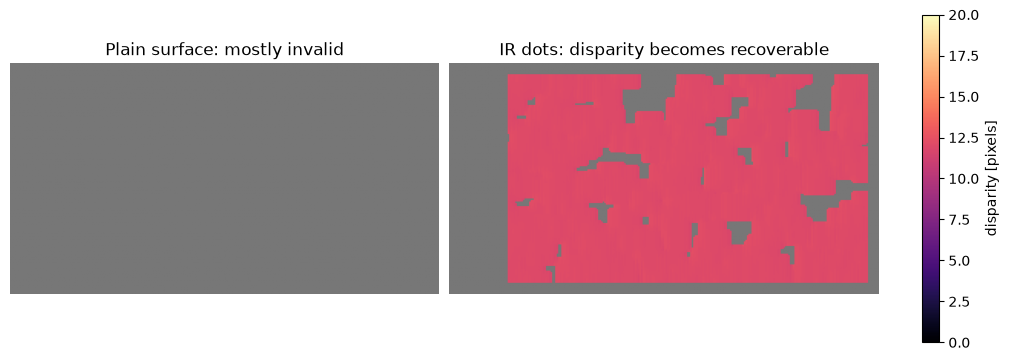

Trusted disparity on plain surface: 0.0%
Trusted disparity with projected dots: 90.6%


In [10]:
rng = np.random.default_rng(4)
height, width = 150, 280
projected_disparity = 12
candidate_disparities = np.arange(0, 25)
match_point = (145, 75)  # Centre of the left-image patch used for the SAD curves.
ir_block_size = 15
ir_num_disparities = 32

# A perfectly plain surface: every local patch looks like every other patch.
plain_left = np.full((height, width), 145, dtype=np.uint8)
plain_right = np.roll(plain_left, -projected_disparity, axis=1)

# The projector adds a fixed dot pattern that both IR cameras can observe.
dotted_left = plain_left.copy()
for x, y in rng.integers([5, 5], [width - 5, height - 5], size=(320, 2)):
    cv2.circle(dotted_left, (int(x), int(y)), 1, int(rng.integers(45, 235)), -1)
dotted_right = np.roll(dotted_left, -projected_disparity, axis=1)

plain_costs = sad_cost_curve(
    plain_left, plain_right, match_point, candidate_disparities, block_size=ir_block_size
)
dotted_costs = sad_cost_curve(
    dotted_left, dotted_right, match_point, candidate_disparities, block_size=ir_block_size
)

fig, axes = plt.subplots(2, 3, figsize=(13, 6), constrained_layout=True)
for row, (left_ir, right_ir, costs, label) in enumerate((
    (plain_left, plain_right, plain_costs, "Plain surface"),
    (dotted_left, dotted_right, dotted_costs, "Projected IR dots"),
)):
    axes[row, 0].imshow(left_ir, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"{label}: left IR camera")
    axes[row, 1].imshow(right_ir, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title(f"{label}: right IR camera")

    # Draw the frozen left patch and its true matching position in the right image.
    patch_radius = ir_block_size // 2
    right_match_point = (match_point[0] - projected_disparity, match_point[1])
    for ax, centre, color in (
        (axes[row, 0], match_point, "#D1495B"),
        (axes[row, 1], right_match_point, "#276FBF"),
    ):
        ax.add_patch(plt.Rectangle(
            (centre[0] - patch_radius, centre[1] - patch_radius),
            ir_block_size,
            ir_block_size,
            fill=False,
            edgecolor=color,
            linewidth=1,
        ))
        ax.scatter(*centre, s=10, color=color)

    axes[row, 2].plot(candidate_disparities, costs, "o-", markersize=3)
    axes[row, 2].axvline(projected_disparity, color="#D1495B", linestyle="--",
                         label=f"true disparity = {projected_disparity} px")
    axes[row, 2].set(xlabel="candidate disparity [pixels]", ylabel="SAD cost")
    axes[row, 2].grid(alpha=0.25)
    axes[row, 2].legend()
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

axes[0, 2].set_title("No unique winner: every shift looks the same")
axes[1, 2].set_title("Dots create a clear matching minimum")
plt.show()

# Ask StereoBM for a dense result on both pairs.
ir_matcher = cv2.StereoBM_create(
    numDisparities=ir_num_disparities,
    blockSize=ir_block_size,
)
ir_matcher.setTextureThreshold(5)
ir_matcher.setUniquenessRatio(8)
plain_disparity = ir_matcher.compute(plain_left, plain_right).astype(np.float32) / 16.0
dotted_disparity = ir_matcher.compute(dotted_left, dotted_right).astype(np.float32) / 16.0

ir_cmap = plt.colormaps["magma"].copy()
ir_cmap.set_bad("#777777")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for ax, disparity, title in zip(
    axes,
    (plain_disparity, dotted_disparity),
    ("Plain surface: mostly invalid", "IR dots: disparity becomes recoverable"),
):
    shown = ax.imshow(np.where(disparity > 0, disparity, np.nan),
                      cmap=ir_cmap, vmin=0, vmax=20)
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(shown, ax=axes, fraction=0.035, label="disparity [pixels]")
plt.show()

# Compare trusted coverage only where the full block and disparity search fit.
radius = ir_block_size // 2
safe_area = np.zeros_like(plain_left, dtype=bool)
safe_area[radius:-radius, ir_num_disparities + radius:-radius] = True
plain_coverage = ((plain_disparity > 0) & safe_area).sum() / safe_area.sum()
dotted_coverage = ((dotted_disparity > 0) & safe_area).sum() / safe_area.sum()
print(f"Trusted disparity on plain surface: {plain_coverage:.1%}")
print(f"Trusted disparity with projected dots: {dotted_coverage:.1%}")

## 7. Keypoints and descriptors: sparse cousins of dense stereo

Dense stereo tries to estimate disparity for many pixels or patches. Keypoint methods first select distinctive locations—often corners—then describe the surrounding appearance as a vector or binary pattern. Similar descriptors can be matched between images.

This produces sparse correspondences rather than a full depth map. It is useful for tracking, image alignment, recognition, visual odometry, and as raw material for later geometry. We use ORB here; handcrafted-feature zoology deserves its own future notebook rather than being smuggled into the final ten minutes.

### ORB controls worth knowing

- `nfeatures` is the **maximum number of strongest keypoints retained**. Asking for more gives ORB more candidates to match, but not necessarily more *good* matches—and a simple image may not contain that many distinctive points.
- `fastThreshold` controls how easily a location becomes a keypoint. Lower values usually find more weak or noisy points; higher values keep only stronger ones.
- `scaleFactor` and `nlevels` control the image pyramid, allowing the same feature to be found at different sizes. Their defaults are a sensible place to remain until scale itself becomes the experiment.
- `patchSize` controls the neighbourhood described around a keypoint; `edgeThreshold` prevents detecting points too close to an edge to fit that neighbourhood. They normally travel together and can continue living under the floorboards for now.

ORB descriptors are binary strings, so `NORM_HAMMING` measures how many bits disagree—appropriate for the default `WTA_K=2`. `crossCheck=True` keeps a match only when each descriptor chooses the other as its best partner. This usually removes suspicious one-sided romances, at the cost of returning fewer matches.

Further reading, mainly to provide comfort through its mere existence: [OpenCV ORB parameters](https://docs.opencv.org/4.x/db/d95/classcv_1_1ORB.html) and [OpenCV feature matching](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html).

### Two ORB knobs, without summoning the whole control panel

We change **one parameter at a time** on the same left image. The first row changes how many of the strongest points ORB may keep. The second changes how easily a point is accepted in the first place. The markers show detected locations; their count is the important part here.

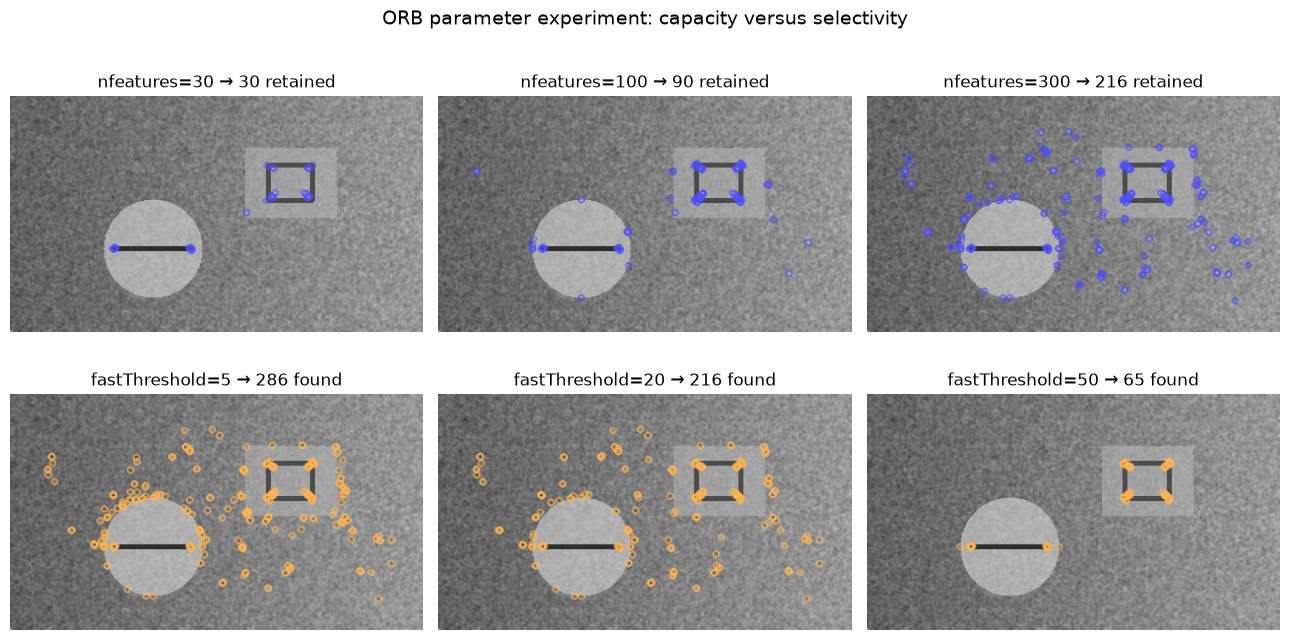

In [26]:
nfeatures_values = [30, 100, 300]
fast_threshold_values = [5, 20, 50]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for ax, nfeatures in zip(axes[0], nfeatures_values):
    detector = cv2.ORB_create(nfeatures=nfeatures, fastThreshold=20)
    keypoints = detector.detect(left, None)
    view = cv2.drawKeypoints(
        left, keypoints, None, color=(255, 80, 80),
        flags=cv2.DRAW_MATCHES_FLAGS_DEFAULT,
    )
    ax.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
    ax.set_title(f"nfeatures={nfeatures} → {len(keypoints)} retained")
    ax.axis("off")

for ax, fast_threshold in zip(axes[1], fast_threshold_values):
    detector = cv2.ORB_create(nfeatures=300, fastThreshold=fast_threshold)
    keypoints = detector.detect(left, None)
    view = cv2.drawKeypoints(
        left, keypoints, None, color=(80, 180, 255),
        flags=cv2.DRAW_MATCHES_FLAGS_DEFAULT,
    )
    ax.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
    ax.set_title(f"fastThreshold={fast_threshold} → {len(keypoints)} found")
    ax.axis("off")

fig.suptitle("ORB parameter experiment: capacity versus selectivity", fontsize=14)
plt.tight_layout()
plt.show()

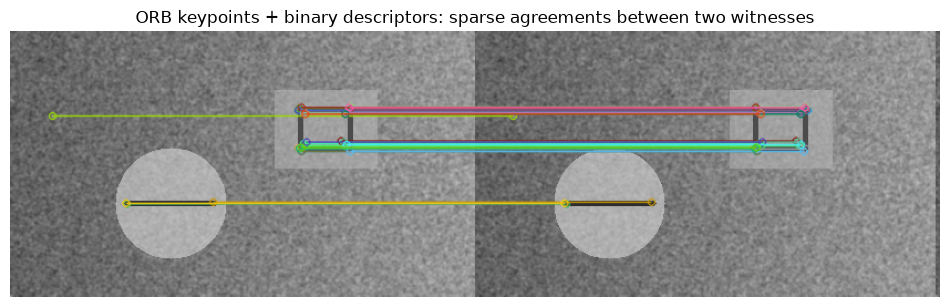

Detected keypoints: left=90, right=90
Median vertical mismatch among shown matches: 0.00 px


In [37]:
orb = cv2.ORB_create(nfeatures=100)  # Maximum strongest keypoints to retain
left_keypoints, left_descriptors = orb.detectAndCompute(left, None)
right_keypoints, right_descriptors = orb.detectAndCompute(right, None)
# ORB descriptors are bits; keep only matches that agree in both directions.
matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = sorted(matcher.match(left_descriptors, right_descriptors), key=lambda match: match.distance)

match_image = cv2.drawMatches(
    left,
    left_keypoints,
    right,
    right_keypoints,
    matches[:35],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
)

plt.figure(figsize=(12, 5))
plt.imshow(cv2.cvtColor(match_image, cv2.COLOR_BGR2RGB))
plt.title("ORB keypoints + binary descriptors: sparse agreements between two witnesses")
plt.axis("off")
plt.show()

vertical_errors = [
    abs(left_keypoints[m.queryIdx].pt[1] - right_keypoints[m.trainIdx].pt[1])
    for m in matches[:35]
]
print(f"Detected keypoints: left={len(left_keypoints)}, right={len(right_keypoints)}")
print(f"Median vertical mismatch among shown matches: {np.median(vertical_errors):.2f} px")

## Possible follow-up experiments

Candidates, not homework delivered by an aggressive depth map:

- Add noise, brightness differences, or vertical misalignment to the stereo pair.
- Compare `StereoBM` with `StereoSGBM`.
- Create a textureless region and measure how active dot texture changes valid disparity coverage.
- Filter ORB matches by the rectified-stereo rule: corresponding points should have similar `y` coordinates.
- Estimate depth only at matched keypoints and compare sparse versus dense reconstruction.
- Add occlusion and inspect which camera sees pixels the other cannot.

## Quick reflection

- Why does rectification reduce matching from a 2D search to a mostly horizontal search?
- Why does a nearby object have larger disparity?
- Why can a large matching block damage object boundaries?
- Which quantities convert disparity from pixels into depth in meters?
- Why does active infrared help on a plain wall?
- What is the difference between a keypoint and its descriptor?

## Takeaway

Stereo depth is not produced by two cameras merely existing near each other. The system must find corresponding evidence, measure disparity, know its calibration, and survive ambiguity, textureless surfaces, occlusion, and noise.

Two cameras can estimate distance. They can also disagree in stereo.